## Exploratory Data Analysis (EDA)

This section performs initial exploratory analysis on the New Jersey accidents dataset. It includes:
- Data shape and brief preview
- Missing value summary
- Target (Severity) distribution
- Time-based features (hour, weekday)
- Numeric correlations
- Top cities/counties/streets


In [47]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)
import warnings
warnings.filterwarnings('ignore')


In [2]:
data = pd.read_csv("data/raw/US_Accidents_March23_NJ.csv")

In [5]:
data.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [7]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')

In [8]:
data.shape

(347960, 46)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960 non-nu

In [12]:
data.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,347960.000000,347960.000000,347960.000000,194902.000000,194902.000000,347960.000000,345892.000000,276306.000000,345769.000000,344976.000000,344879.000000,330081.000000,261449.000000
mean,2.259550,41.560975,-74.556611,41.536836,-74.526908,0.751562,54.840956,49.544803,65.880507,29.813697,8.969948,8.999994,0.023959
std,0.511014,0.999105,1.574805,0.999496,1.528085,2.124309,19.336263,23.010782,20.201403,0.382717,2.827488,5.542104,0.401378
min,1.000000,40.503048,-79.761920,40.505200,-79.761981,0.000000,-77.800000,-39.000000,1.000000,19.750000,0.000000,0.000000,0.000000
25%,2.000000,40.758131,-74.088270,40.750500,-74.076729,0.000000,39.000000,31.000000,50.000000,29.600000,10.000000,5.000000,0.000000
50%,2.000000,40.976681,-73.894638,40.918790,-73.903030,0.069000,56.000000,52.000000,66.000000,29.870000,10.000000,8.000000,0.000000
75%,2.000000,42.743330,-73.760542,42.714843,-73.769342,0.713000,71.000000,69.000000,84.000000,30.070000,10.000000,12.000000,0.000000
max,4.000000,45.001892,-71.861031,44.997320,-71.943680,112.903000,172.000000,172.000000,100.000000,30.890000,105.000000,175.000000,10.160000


In [13]:
missing = data.isnull().sum().sort_values(ascending=False)
missing

End_Lat                  153058
End_Lng                  153058
Precipitation(in)         86511
Wind_Chill(F)             71654
Wind_Speed(mph)           17879
Wind_Direction             4477
Visibility(mi)             3081
Pressure(in)               2984
Weather_Condition          2726
Humidity(%)                2191
Temperature(F)             2068
Weather_Timestamp          1459
Nautical_Twilight           710
Civil_Twilight              710
Sunrise_Sunset              710
Astronomical_Twilight       710
Street                      648
Airport_Code                347
City                         28
Description                   1
Traffic_Signal                0
Railway                       0
Roundabout                    0
Station                       0
Stop                          0
Traffic_Calming               0
Country                       0
Junction                      0
Turning_Loop                  0
End_Time                      0
Start_Time                    0
Severity

In [15]:
missing = data.isnull().sum().sort_values(ascending=False)
missing_percent= missing/len(data)
missing_percent

End_Lat                  0.439872
End_Lng                  0.439872
Precipitation(in)        0.248623
Wind_Chill(F)            0.205926
Wind_Speed(mph)          0.051382
Wind_Direction           0.012866
Visibility(mi)           0.008854
Pressure(in)             0.008576
Weather_Condition        0.007834
Humidity(%)              0.006297
Temperature(F)           0.005943
Weather_Timestamp        0.004193
Nautical_Twilight        0.002040
Civil_Twilight           0.002040
Sunrise_Sunset           0.002040
Astronomical_Twilight    0.002040
Street                   0.001862
Airport_Code             0.000997
City                     0.000080
Description              0.000003
Traffic_Signal           0.000000
Railway                  0.000000
Roundabout               0.000000
Station                  0.000000
Stop                     0.000000
Traffic_Calming          0.000000
Country                  0.000000
Junction                 0.000000
Turning_Loop             0.000000
End_Time      

In [35]:
missing = data.isnull().sum().sort_values(ascending=False)
missing.head()

End_Lat              153058
End_Lng              153058
Precipitation(in)     86511
Wind_Chill(F)         71654
Wind_Speed(mph)       17879
dtype: int64

In [36]:
# Drop columns with too many missing values (e.g. >40%)
data_new = data.dropna(axis=1, thresh=len(data)*0.6)

#removing End_Lat and End_Lng 

In [37]:
data_new.shape

(347960, 44)

In [38]:
data_new.isnull().sum().sort_values(ascending=False)

Precipitation(in)        86511
Wind_Chill(F)            71654
Wind_Speed(mph)          17879
Wind_Direction            4477
Visibility(mi)            3081
Pressure(in)              2984
Weather_Condition         2726
Humidity(%)               2191
Temperature(F)            2068
Weather_Timestamp         1459
Nautical_Twilight          710
Civil_Twilight             710
Sunrise_Sunset             710
Astronomical_Twilight      710
Street                     648
Airport_Code               347
City                        28
Description                  1
Country                      0
Traffic_Calming              0
Railway                      0
Roundabout                   0
Station                      0
Stop                         0
Turning_Loop                 0
Traffic_Signal               0
Junction                     0
End_Time                     0
Start_Time                   0
Severity                     0
No_Exit                      0
Crossing                     0
Give_Way

In [54]:
duplicates = data_new[data_new.duplicated()]

In [55]:
duplicates # no duplicates

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight


In [56]:
data_new = data_new.drop_duplicates() # remove if duplicate rows are there

In [39]:
data_new["Severity"].value_counts()

2    265902
3     70062
4     10749
1      1247
Name: Severity, dtype: int64

In [27]:
data_new["Severity"].unique()

array([3, 2, 4, 1], dtype=int64)

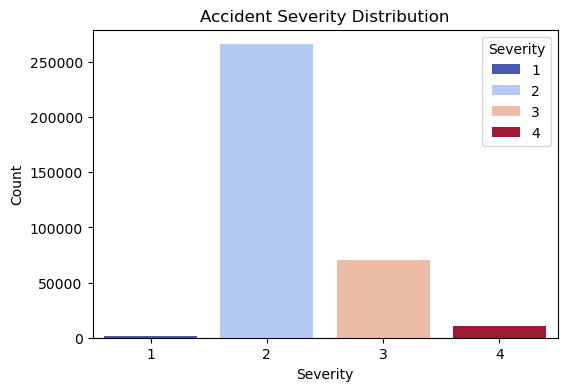


Severity counts:


2    265902
3     70062
4     10749
1      1247
Name: Severity, dtype: int64

In [33]:
plt.figure(figsize=(6,4))
sns.countplot(x='Severity', data=data, palette='coolwarm', hue = 'Severity')
plt.title('Accident Severity Distribution')
plt.ylabel('Count')
plt.show()
print('\nSeverity counts:')
display(data['Severity'].value_counts())

In [40]:
data_new["Start_Time"].value_counts


<bound method IndexOpsMixin.value_counts of 0         2016-11-30 16:25:41
1         2016-11-30 15:40:06
2         2016-11-30 15:26:18
3         2016-11-30 16:14:11
4         2016-11-30 16:17:57
                 ...         
347955    2019-08-23 16:48:32
347956    2019-08-23 16:16:21
347957    2019-08-23 16:40:16
347958    2019-08-23 19:20:28
347959    2019-08-23 17:51:33
Name: Start_Time, Length: 347960, dtype: object>

In [50]:
# convert start_time and end_time into datetime 
data_new['Start_Time'] = pd.to_datetime(data['Start_Time'], errors='coerce') #errors='coerce'-Invalid parsing - NaT (Not a Time)

data_new['End_Time'] = pd.to_datetime(data['End_Time'], errors='coerce') #errors='coerce'-Invalid parsing - NaT (Not a Time)


In [53]:
data_new['Weather_Condition'].value_counts

<bound method IndexOpsMixin.value_counts of 0              Overcast
1              Overcast
2            Light Rain
3                  Rain
4                  Rain
              ...      
347955           Cloudy
347956    Partly Cloudy
347957             Fair
347958    Mostly Cloudy
347959           Cloudy
Name: Weather_Condition, Length: 347960, dtype: object>

In [51]:
data_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 44 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   ID                     347960 non-null  object        
 1   Source                 347960 non-null  object        
 2   Severity               347960 non-null  int64         
 3   Start_Time             347960 non-null  datetime64[ns]
 4   End_Time               347960 non-null  datetime64[ns]
 5   Start_Lat              347960 non-null  float64       
 6   Start_Lng              347960 non-null  float64       
 7   Distance(mi)           347960 non-null  float64       
 8   Description            347959 non-null  object        
 9   Street                 347312 non-null  object        
 10  City                   347932 non-null  object        
 11  County                 347960 non-null  object        
 12  State                  347960 non-null  obje